# 01 — Vérification exploratoire (Jalon 1)

Deux questions de cadrage à trancher avant le feature engineering :

1. **`Load_Type`** est-il défini par la tranche horaire / le calendrier (utilisable comme feature) ou dérivé de la consommation (fuite de cible) ?
2. **Fuite physique** : `Usage_kWh` se déduit-il de la puissance réactive et du facteur de puissance du même intervalle ? Si oui, cela justifie la prévision à *t + 1 h*.

Prérequis : `dvc pull` (ou `dvc repro`) pour disposer de `data/raw/steel_industry_data.csv`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

from steelwatt.data.validate import parse_timestamps

ROOT = Path.cwd() if (Path.cwd() / 'dvc.yaml').exists() else Path.cwd().parent
df = pd.read_csv(ROOT / 'data/raw/steel_industry_data.csv')
df['ts'] = parse_timestamps(df['date'])  # fin d'intervalle, minuit corrigé
start = df['ts'] - pd.Timedelta('15min')  # début d'intervalle
df['day'] = start.dt.normalize()
df['slot_h'] = (start - df['day']).dt.total_seconds() / 3600
df['month'] = df['day'].dt.month

LOADS = ['Light_Load', 'Medium_Load', 'Maximum_Load']
COLORS = {'Light_Load': '#2a78d6', 'Medium_Load': '#eb6834', 'Maximum_Load': '#1baf7a'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e5e0',
                     'axes.axisbelow': True, 'figure.dpi': 110})
df.shape

Matplotlib is building the font cache; this may take a moment.


(35040, 15)

## 1. Part de chaque `Load_Type`

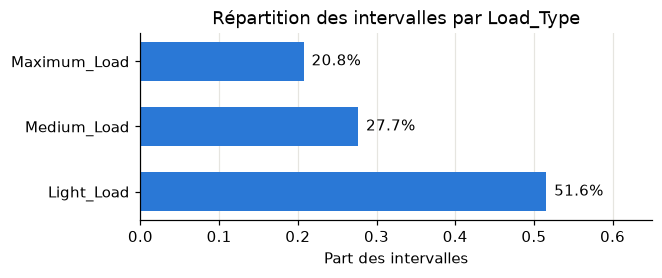

Load_Type
Light_Load      0.5158
Medium_Load     0.2767
Maximum_Load    0.2075
Name: proportion, dtype: float64

In [2]:
share = df['Load_Type'].value_counts(normalize=True).reindex(LOADS)
fig, ax = plt.subplots(figsize=(6, 2.2))
ax.barh(share.index, share.values, color='#2a78d6', height=0.6)
for i, v in enumerate(share.values):
    ax.text(v + 0.01, i, f'{v:.1%}', va='center')
ax.set_xlim(0, 0.65); ax.set_xlabel('Part des intervalles'); ax.grid(axis='y')
ax.set_title('Répartition des intervalles par Load_Type'); plt.show()
share.round(4)

## 2. `Load_Type` × heure : une grille calendaire ?

Chaque ligne de la carte ci-dessous est un jour, chaque colonne un créneau de 15 min. Une grille régulière (bandes verticales) indique un calendrier ; un motif bruité indiquerait un seuil sur la consommation.

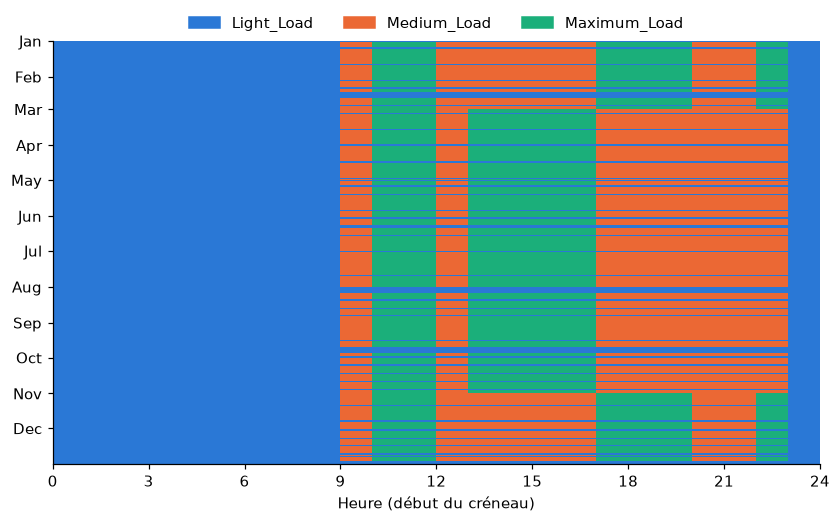

In [3]:
code_map = {k: i for i, k in enumerate(LOADS)}
grid = (df.assign(c=df['Load_Type'].map(code_map))
          .pivot_table(index='day', columns='slot_h', values='c'))
fig, ax = plt.subplots(figsize=(9, 5))
ax.imshow(grid.values, aspect='auto', interpolation='nearest',
          cmap=ListedColormap([COLORS[k] for k in LOADS]),
          extent=[0, 24, len(grid), 0])
months = pd.date_range('2018-01-01', periods=12, freq='MS')
ax.set_yticks([(m - grid.index[0]).days for m in months],
              [m.strftime('%b') for m in months])
ax.set_xticks(range(0, 25, 3)); ax.set_xlabel('Heure (début du créneau)')
ax.grid(False)
handles = [plt.Rectangle((0, 0), 1, 1, color=COLORS[k]) for k in LOADS]
ax.legend(handles, LOADS, loc='upper center', bbox_to_anchor=(0.5, 1.09),
          ncol=3, frameon=False)
plt.show()

In [4]:
# Jours « chômés » : aucun créneau Medium/Maximum entre 10 h et 22 h.
day_hours = df[(df['slot_h'] >= 10) & (df['slot_h'] < 22)]
off = day_hours.groupby('day')['Load_Type'].apply(lambda s: (s == 'Light_Load').all())
off_days = off[off].index
df['day_type'] = np.where(df['day'].isin(off_days), 'off', 'work')
print(f'{len(off_days)} jours chômés :',
      pd.Series(off_days.day_name()).value_counts().to_dict())

def mode_accuracy(keys):
    """Part des lignes expliquée par la modalité majoritaire de chaque groupe."""
    top = df.groupby(keys)['Load_Type'].agg(lambda s: s.value_counts().iloc[0])
    return top.sum() / len(df)

purity = pd.Series({
    'créneau': mode_accuracy(['slot_h']),
    'créneau + WeekStatus': mode_accuracy(['slot_h', 'WeekStatus']),
    'créneau + jour ouvré/chômé': mode_accuracy(['slot_h', 'day_type']),
    'créneau + jour ouvré/chômé + mois': mode_accuracy(['slot_h', 'day_type', 'month']),
}, name='part expliquée')
purity.round(4)

62 jours chômés : {'Sunday': 35, 'Saturday': 14, 'Monday': 3, 'Wednesday': 3, 'Tuesday': 3, 'Thursday': 2, 'Friday': 2}


créneau                              0.8142
créneau + WeekStatus                 0.8224
créneau + jour ouvré/chômé           0.9132
créneau + jour ouvré/chômé + mois    1.0000
Name: part expliquée, dtype: float64

In [5]:
# Profils distincts de journée ouvrée et leurs périodes de validité
sig = (df[df['day_type'] == 'work'].groupby('day')['Load_Type']
         .agg(lambda s: ''.join(x[1] for x in s)))
profile_id = sig.map({p: i for i, p in enumerate(sig.unique())})
blocks = (profile_id != profile_id.shift()).cumsum()
pd.DataFrame([{'du': g.index[0].date(), 'au': g.index[-1].date(),
               'jours ouvrés': len(g), 'profil': int(g.iloc[0])}
              for _, g in profile_id.groupby(blocks)])

,du,au,jours ouvrés,profil
0,2018-01-02,2018-02-28,46,0
1,2018-03-01,2018-10-31,208,1
2,2018-11-01,2018-12-28,49,0


## 3. `Load_Type` dépend-il de la consommation ?

Si `Load_Type` était un seuil sur `Usage_kWh`, les distributions ne se recouvriraient pas.

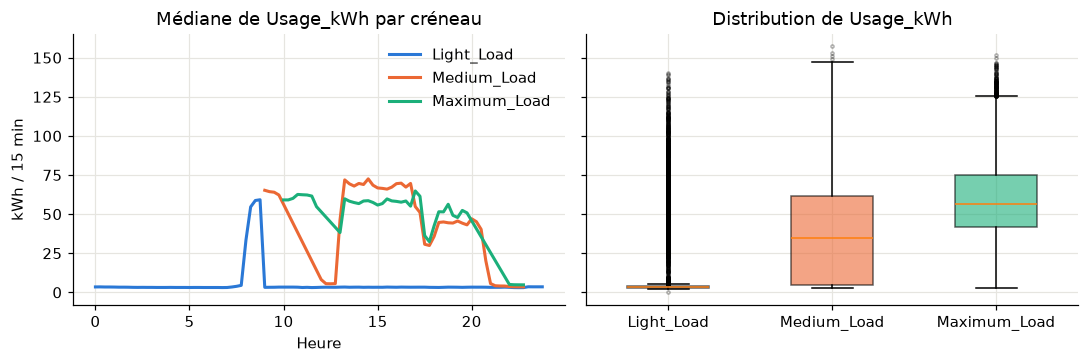

,count,mean,std,min,25%,50%,75%,max
Load_Type,,,,,,,,
Light_Load,18072.0,8.63,17.91,0.00,2.95,3.31,4.03,140.29
Medium_Load,9696.0,38.45,35.22,2.52,4.42,34.44,61.70,157.18
Maximum_Load,7272.0,59.27,29.75,2.92,42.00,56.63,75.31,151.67


Light_Load avec Usage > 50 kWh     915
Maximum_Load avec Usage < 5 kWh    365
dtype: int64

In [6]:
work_hours = df[(df['day_type'] == 'work') & df['slot_h'].between(10, 22, 'left')]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for lt in LOADS:
    med = df[df['Load_Type'] == lt].groupby('slot_h')['Usage_kWh'].median()
    axes[0].plot(med.index, med.values, lw=2, color=COLORS[lt], label=lt)
axes[0].set_title('Médiane de Usage_kWh par créneau'); axes[0].set_xlabel('Heure')
axes[0].set_ylabel('kWh / 15 min'); axes[0].legend(frameon=False)
data = [df.loc[df['Load_Type'] == lt, 'Usage_kWh'] for lt in LOADS]
bp = axes[1].boxplot(data, tick_labels=LOADS, patch_artist=True, widths=0.5,
                     flierprops={'markersize': 2, 'alpha': 0.3})
for patch, lt in zip(bp['boxes'], LOADS):
    patch.set_facecolor(COLORS[lt]); patch.set_alpha(0.6)
axes[1].set_title('Distribution de Usage_kWh'); plt.tight_layout(); plt.show()

overlap = pd.Series({
    'Light_Load avec Usage > 50 kWh': int(((df['Load_Type'] == 'Light_Load') & (df['Usage_kWh'] > 50)).sum()),
    'Maximum_Load avec Usage < 5 kWh': int(((df['Load_Type'] == 'Maximum_Load') & (df['Usage_kWh'] < 5)).sum()),
})
display(df.groupby('Load_Type')['Usage_kWh'].describe().reindex(LOADS).round(2))
overlap

## 4. Fuite physique : `Usage_kWh` ← puissance réactive & facteur de puissance

Avec $\cos\varphi = PF/100$ et $Q$ la puissance réactive inductive : $P = Q \cdot \dfrac{\cos\varphi}{\sqrt{1-\cos^2\varphi}}$ (défini si $PF < 100$ et $Q > 0$).

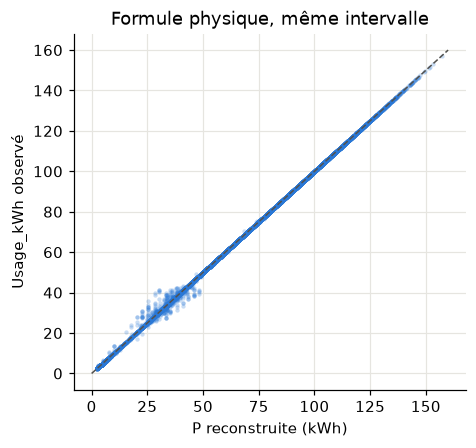

couverture (PF<100 et Q>0)      0.7867
R²                              0.9999
MAE (kWh)                       0.0479
erreur absolue médiane (kWh)    0.0006
corr(CO2, Usage)                0.9882
dtype: float64

In [7]:
y = df['Usage_kWh']
pf = df['Lagging_Current_Power_Factor'] / 100
q = df['Lagging_Current_Reactive.Power_kVarh']
ok = (pf < 1) & (q > 0)
p_hat = q * pf / np.sqrt(1 - pf**2)
fig, ax = plt.subplots(figsize=(4.6, 4.2))
ax.scatter(p_hat[ok], y[ok], s=8, alpha=0.25, color='#2a78d6', lw=0)
ax.plot([0, 160], [0, 160], color='#52514e', lw=1, ls='--')
ax.set_xlabel('P reconstruite (kWh)'); ax.set_ylabel('Usage_kWh observé')
ax.set_title('Formule physique, même intervalle'); plt.show()
pd.Series({'couverture (PF<100 et Q>0)': ok.mean(),
           'R²': r2_score(y[ok], p_hat[ok]),
           'MAE (kWh)': mean_absolute_error(y[ok], p_hat[ok]),
           'erreur absolue médiane (kWh)': np.median(np.abs(y[ok] - p_hat[ok])),
           'corr(CO2, Usage)': df['CO2(tCO2)'].corr(y)}).round(4)

### Même intervalle vs *t + 1 h* (train jan.–août, validation sept.–oct.)

On entraîne une forêt aléatoire **uniquement sur les grandeurs électriques de l'intervalle courant** (sans `CO2`), une fois pour prédire `Usage_kWh` au même instant, une fois pour *t + 1 h* (4 pas). La persistance naïve sert de référence. Il s'agit d'un diagnostic de fuite, pas de la baseline du Jalon 2.

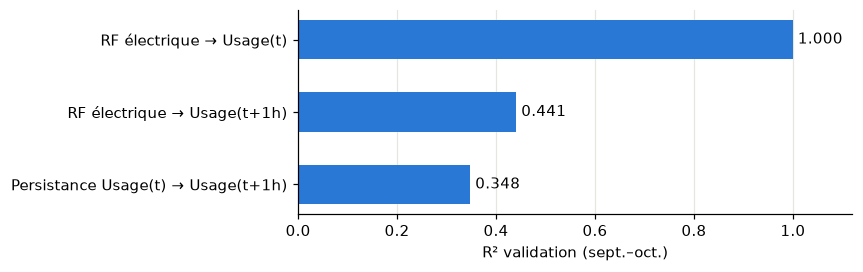

,R²,MAE (kWh)
RF électrique → Usage(t),1.000,0.206
RF électrique → Usage(t+1h),0.441,13.443
Persistance Usage(t) → Usage(t+1h),0.348,12.504


In [8]:
elec = ['Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh',
        'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor']
train = df['ts'] < '2018-09-01'
val = (df['ts'] >= '2018-09-01') & (df['ts'] < '2018-11-01')
y_1h = y.shift(-4)
has = y_1h.notna()
rf = RandomForestRegressor(200, min_samples_leaf=2, n_jobs=-1, random_state=0)
rows = {}
rf.fit(df.loc[train, elec], y[train])
pred = rf.predict(df.loc[val, elec])
rows['RF électrique → Usage(t)'] = (r2_score(y[val], pred), mean_absolute_error(y[val], pred))
rf.fit(df.loc[train & has, elec], y_1h[train & has])
pred = rf.predict(df.loc[val & has, elec])
rows['RF électrique → Usage(t+1h)'] = (r2_score(y_1h[val & has], pred),
                                       mean_absolute_error(y_1h[val & has], pred))
rows['Persistance Usage(t) → Usage(t+1h)'] = (
    r2_score(y_1h[val & has], y[val & has]),
    mean_absolute_error(y_1h[val & has], y[val & has]))
leak = pd.DataFrame(rows, index=['R²', 'MAE (kWh)']).T.round(3)

fig, ax = plt.subplots(figsize=(6.5, 2.4))
ax.barh(leak.index[::-1], leak['R²'][::-1], color='#2a78d6', height=0.55)
for i, v in enumerate(leak['R²'][::-1]):
    ax.text(v + 0.01, i, f'{v:.3f}', va='center')
ax.set_xlim(0, 1.12); ax.set_xlabel('R² validation (sept.–oct.)'); ax.grid(axis='y')
plt.show()
leak

## Conclusions

**`Load_Type` = calendrier, pas consommation → conservé comme feature.**

* Il est entièrement déterminé par *(créneau de 15 min, jour ouvré/chômé, saison)* : 100 % des lignes sont expliquées par la modalité majoritaire de chaque groupe, et il n'existe que **2 profils** de journée ouvrée, qui basculent au **1er mars** et au **1er novembre** (saisons tarifaires été / hiver, typiques d'une grille horaire de type KEPCO).
* 0 h–9 h est toujours `Light_Load`. Les jours chômés (dimanches, jours fériés coréens, certains samedis) sont `Light_Load` toute la journée.
* Les distributions de consommation se recouvrent fortement : des `Light_Load` dépassent 50 kWh et des `Maximum_Load` passent sous 5 kWh. Ce n'est donc pas un seuil sur `Usage_kWh`.
* Point d'attention : `WeekStatus` ne suffit pas à reconstruire `Load_Type`, car les jours fériés et certains samedis sont chômés. Au Jalon 2, on pourra ajouter un indicateur « jour chômé » issu du calendrier usine.

**Fuite de cible confirmée → prévision à *t + 1 h* justifiée.**

* La formule $P = Q\cos\varphi/\sqrt{1-\cos^2\varphi}$ reconstruit `Usage_kWh` du même intervalle avec un R² ≈ 0,9999 (erreur médiane ≈ 0,001 kWh) sur les ~79 % de lignes où elle est définie. Une forêt sur les seules grandeurs électriques courantes atteint R² ≈ 0,9996.
* Pour l'intervalle **t + 1 h**, ces mêmes grandeurs tombent à R² ≈ 0,44, du même ordre que la persistance naïve (R² ≈ 0,35, MAE ≈ 12,5 kWh). La tâche devient donc une vraie prévision.
* `CO2(tCO2)` est corrélé à 0,988 avec la cible : son exclusion est confirmée.
* Conséquence pour le Jalon 2 : la persistance donne une MAE d'environ 12,5 kWh en validation, ce qui rend l'objectif de MAE ≤ 5 kWh très ambitieux. Il faudra le recalibrer après la baseline, comme le prévoit le synopsis.